In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths
from google.colab import drive
from scipy.optimize import curve_fit
# Montar Google Drive
drive.mount('/content/drive')


Mounted at /content/drive


/tmp/ipython-input-3648950312.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


Os valores dos picos são: [336.65 357.2  486.31 656.09 776.99]


/tmp/ipython-input-3648950312.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


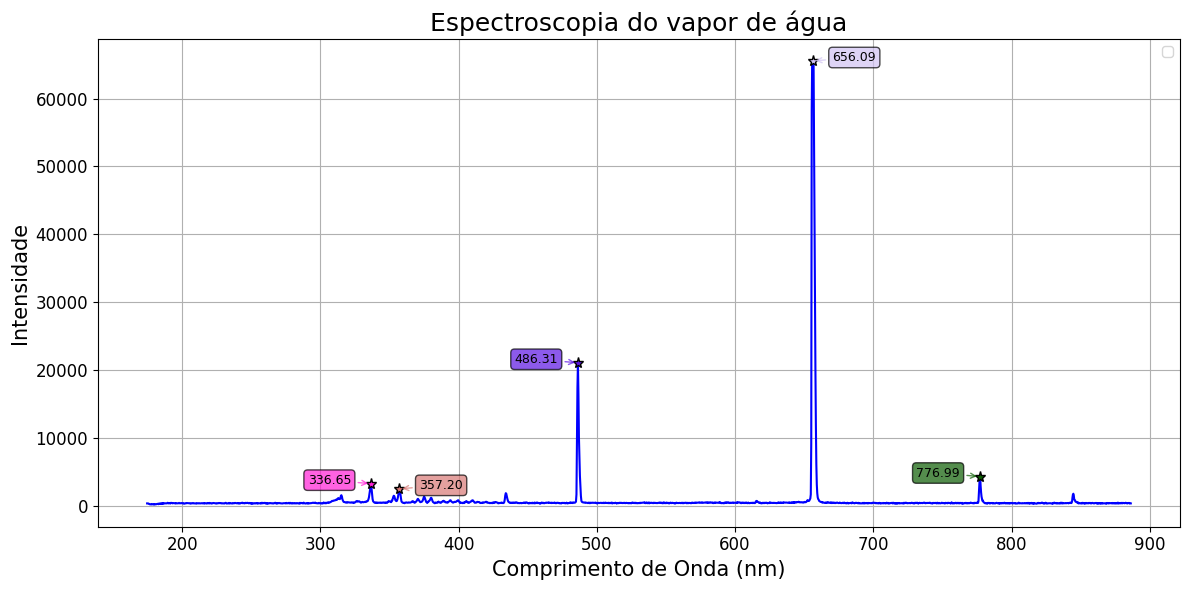

Pico em x = 336.65 ± 0.39 (FWHM = 1.90)
Pico em x = 357.20 ± 0.38 (FWHM = 1.88)
Pico em x = 486.31 ± 0.30 (FWHM = 1.45)
Pico em x = 656.09 ± 0.58 (FWHM = 2.85)
Pico em x = 776.99 ± 0.34 (FWHM = 1.68)


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/H2O_LAMBDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=2000)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)

# Estética do gráfico
plt.grid(True)
plt.title("Espectroscopia do vapor de água",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-216849358.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-216849358.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Os valores dos picos são: [434.1  486.31 656.09]


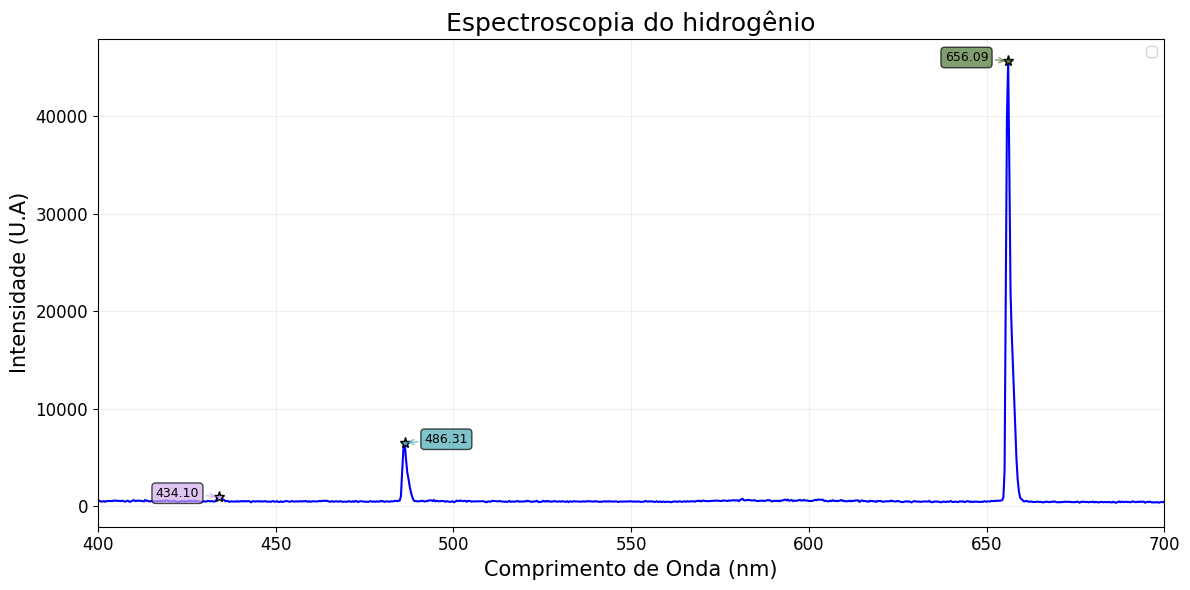

Pico em x = 434.10 ± 0.39 (FWHM = 1.93)
Pico em x = 486.31 ± 0.33 (FWHM = 1.62)
Pico em x = 656.09 ± 0.31 (FWHM = 1.51)


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/H_LAMBDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=900)
picos_filtrados = [p for p in todos_picos if x[p] > 400]
valores_picos = x[picos_filtrados]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(picos_filtrados))]

# Anotar os picos no gráfico
for i, pico in enumerate(picos_filtrados):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)

# Estética do gráfico
plt.grid(alpha=0.2)
plt.title("Espectroscopia do hidrogênio",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade (U.A)",fontsize=15)
plt.legend()
plt.xlim(400, 700)
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig("Espectroscopia do hidrogênio.pdf", format="pdf", dpi=300, bbox_inches="tight")
plt.show()


# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, picos_filtrados, rel_height=0.5)

for i, idx in enumerate(picos_filtrados):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-3427312033.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


Os valores dos picos são: [557.14 586.88 758.51 760.11 769.36 785.22 805.96 811.27 819.06 826.5
 828.05 829.9  851.11 878.13]


/tmp/ipython-input-3427312033.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


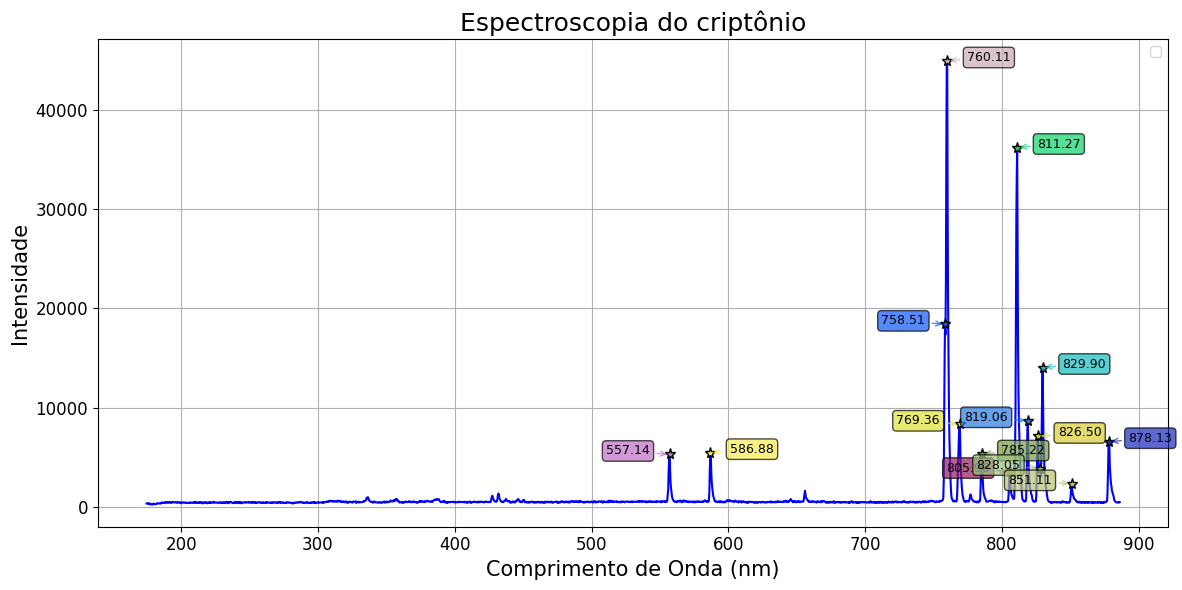

Pico em x = 557.14 ± 0.33 (FWHM = 1.59)
Pico em x = 586.88 ± 0.32 (FWHM = 1.57)
Pico em x = 758.51 ± 0.05 (FWHM = 0.25)
Pico em x = 760.11 ± 0.38 (FWHM = 1.87)
Pico em x = 769.36 ± 0.46 (FWHM = 2.25)
Pico em x = 785.22 ± 0.33 (FWHM = 1.64)
Pico em x = 805.96 ± 0.31 (FWHM = 1.53)
Pico em x = 811.27 ± 0.38 (FWHM = 1.86)
Pico em x = 819.06 ± 0.33 (FWHM = 1.63)
Pico em x = 826.50 ± 0.23 (FWHM = 1.15)
Pico em x = 828.05 ± 0.06 (FWHM = 0.27)
Pico em x = 829.90 ± 0.35 (FWHM = 1.71)
Pico em x = 851.11 ± 0.36 (FWHM = 1.75)
Pico em x = 878.13 ± 0.43 (FWHM = 2.09)


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/KR_LAMBDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=2000)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)

# Estética do gráfico
plt.grid(True)
plt.title("Espectroscopia do criptônio",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/NE_LAMDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=2000)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)

# Estética do gráfico
plt.grid(True)
plt.title("Espectroscopia do neon",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-4228551156.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/NE_LAMDA1.txt'

Os valores dos picos são: [312.19 323.5  325.76 329.52 333.27 334.78 335.53 337.4  341.15 343.76
 344.89 348.25 351.24 353.1  355.34 357.95 360.55 363.16 369.1  373.18
 381.69 391.29 393.86 399.75 404.89 406.36 408.19 411.85 419.16 420.26
 422.08 425.36 426.09 427.18 430.1  431.55 435.55 438.81 443.53 444.61
 446.42 447.15 450.76 456.18 457.98 460.5  468.77 470.92 473.79 474.87
 475.94 477.02 483.1  487.38 489.16 489.88 490.59 493.8  496.64 497.35
 500.19 505.87 507.29 514.36 519.31 526.35 527.76 535.48 537.94 538.99
 542.49 543.19 544.24 544.93 545.98 546.68 548.43 551.56 560.26 564.78
 568.24 574.47 575.85 576.54 577.92 578.61 579.3  580.34 583.44 584.47
 585.16 585.85 586.88 587.57 588.94 589.97 590.66 592.38 596.15 601.63
 604.36 607.09 611.53 613.57 614.25 615.61 618.33 619.69 620.71 621.72
 622.4  623.08 628.16 634.24 636.27 640.65 643.   644.35 645.02 646.7
 647.37 649.72 650.39 654.75 656.09 656.76 657.76 659.1  661.1  664.44
 666.1  667.1  669.76 671.09 672.42 673.09 674.75 67

/tmp/ipython-input-3308756608.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


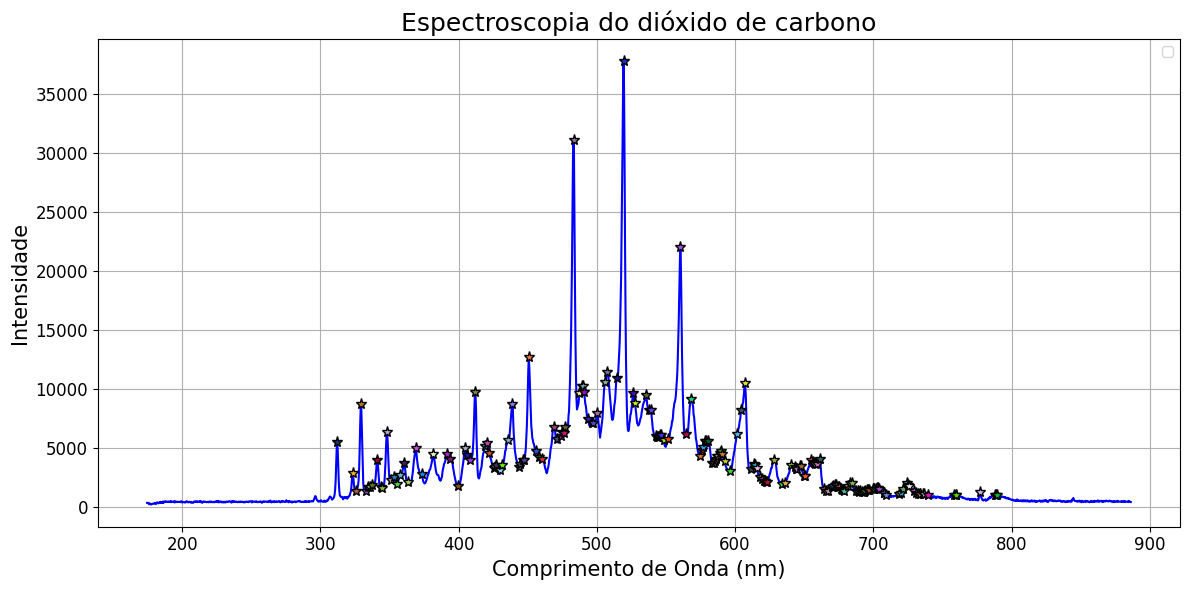

Pico em x = 312.19 ± 0.37 (FWHM = 1.82)
Pico em x = 323.50 ± 0.31 (FWHM = 1.50)
Pico em x = 325.76 ± 0.08 (FWHM = 0.39)
Pico em x = 329.52 ± 0.38 (FWHM = 1.88)
Pico em x = 333.27 ± 0.05 (FWHM = 0.23)
Pico em x = 334.78 ± 0.04 (FWHM = 0.21)
Pico em x = 335.53 ± 0.05 (FWHM = 0.25)
Pico em x = 337.40 ± 0.21 (FWHM = 1.03)
Pico em x = 341.15 ± 0.42 (FWHM = 2.04)
Pico em x = 343.76 ± 0.07 (FWHM = 0.34)
Pico em x = 344.89 ± 0.05 (FWHM = 0.26)
Pico em x = 348.25 ± 0.42 (FWHM = 2.06)
Pico em x = 351.24 ± 0.08 (FWHM = 0.41)
Pico em x = 353.10 ± 0.28 (FWHM = 1.38)
Pico em x = 355.34 ± 0.06 (FWHM = 0.31)
Pico em x = 357.95 ± 0.06 (FWHM = 0.30)
Pico em x = 360.55 ± 0.54 (FWHM = 2.63)
Pico em x = 363.16 ± 0.06 (FWHM = 0.30)
Pico em x = 369.10 ± 0.70 (FWHM = 3.44)
Pico em x = 373.18 ± 0.06 (FWHM = 0.29)
Pico em x = 381.69 ± 0.76 (FWHM = 3.71)
Pico em x = 391.29 ± 1.59 (FWHM = 7.80)
Pico em x = 393.86 ± 0.19 (FWHM = 0.95)
Pico em x = 399.75 ± 0.10 (FWHM = 0.48)
Pico em x = 404.89 ± 0.41 (FWHM = 2.00)


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/CO2_LAMBDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delimiter='\t',
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'])

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=1000)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0


# Estética do gráfico
plt.grid(True)
plt.title("Espectroscopia do dióxido de carbono",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-1726667536.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


Os valores dos picos são: [415.87 420.26 696.56 706.73 714.57 727.26 738.59 751.47 763.63 772.54
 794.99 801.58 811.59 826.81 842.84 852.64 853.25 867.55 868.77 869.37]


/tmp/ipython-input-1726667536.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


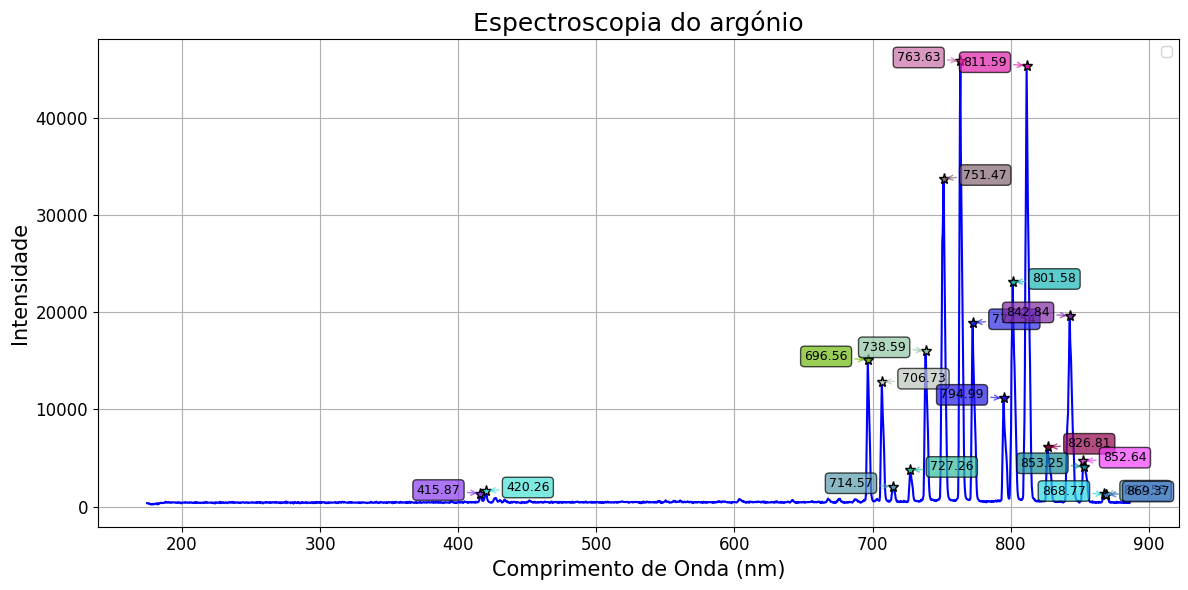

Pico em x = 415.87 ± 0.28 (FWHM = 1.35)
Pico em x = 420.26 ± 0.37 (FWHM = 1.79)
Pico em x = 696.56 ± 0.50 (FWHM = 2.45)
Pico em x = 706.73 ± 0.52 (FWHM = 2.54)
Pico em x = 714.57 ± 0.60 (FWHM = 2.94)
Pico em x = 727.26 ± 0.57 (FWHM = 2.79)
Pico em x = 738.59 ± 0.59 (FWHM = 2.87)
Pico em x = 751.47 ± 0.65 (FWHM = 3.16)
Pico em x = 763.63 ± 0.53 (FWHM = 2.62)
Pico em x = 772.54 ± 0.56 (FWHM = 2.76)
Pico em x = 794.99 ± 0.59 (FWHM = 2.87)
Pico em x = 801.58 ± 0.70 (FWHM = 3.42)
Pico em x = 811.59 ± 0.69 (FWHM = 3.36)
Pico em x = 826.81 ± 0.84 (FWHM = 4.11)
Pico em x = 842.84 ± 0.77 (FWHM = 3.77)
Pico em x = 852.64 ± 0.94 (FWHM = 4.63)
Pico em x = 853.25 ± 0.08 (FWHM = 0.37)
Pico em x = 867.55 ± 1.05 (FWHM = 5.13)
Pico em x = 868.77 ± 0.06 (FWHM = 0.27)
Pico em x = 869.37 ± 0.07 (FWHM = 0.34)


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/AR_LAMBDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=1000)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)

# Estética do gráfico
plt.grid(True)
plt.title("Espectroscopia do argónio",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")



Constante de Rydberg estimada: 1.0970e+07 ± 1.8011e+03 m⁻¹
Valor tabelado: 1.0974e+07 m⁻¹
Desvio relativo: -0.038%


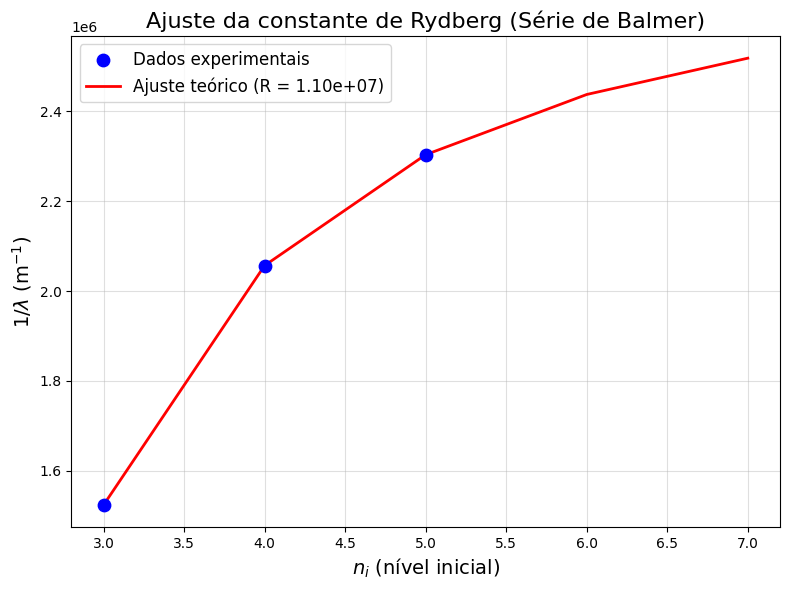

In [ ]:
#  picos detectados!
valores_picos = np.array([434.1, 486.31, 656.09])  # nm
pico_err = np.array([0.5, 0.5, 0.5])


# --------------------------
# Gerar transições da série de Balmer (nf = 2)
def gerar_transicoes_balmer(Z=1, n_max=10, R=1.0973731568508e7):
    transicoes = []
    for n_i in range(3, n_max+1):
        n_f = 2
        inv_lambda = R * Z**2 * (1/n_f**2 - 1/n_i**2)
        lambda_nm = 1e9 / inv_lambda
        transicoes.append((Z, n_i, n_f, lambda_nm))
    return pd.DataFrame(transicoes, columns=["Z", "n_i", "n_f", "lambda_nm"])

df_teo = gerar_transicoes_balmer(Z=1, n_max=10)

# --------------------------
# Casamento automático pico ↔ transição
pares = []
for pico in valores_picos:
    idx = np.argmin(np.abs(df_teo["lambda_nm"] - pico))
    pares.append((pico, *df_teo.iloc[idx]))

df_match = pd.DataFrame(pares, columns=["lambda_exp", "Z", "n_i", "n_f", "lambda_teo"])

# --------------------------
# Ajuste da constante de Rydberg
def modelo(x, R):
    Z, n_i, n_f = x
    return R * Z**2 * (1/n_f**2 - 1/n_i**2)

xdata = np.array([df_match["Z"].values,
                  df_match["n_i"].values,
                  df_match["n_f"].values])
ydata = 1 / (df_match["lambda_exp"].values * 1e-9)

popt, pcov = curve_fit(modelo, xdata, ydata, p0=[1.1e7])
R_est = popt[0]
erro_R = np.sqrt(np.diag(pcov))[0]

print(f"\nConstante de Rydberg estimada: {R_est:.4e} ± {erro_R:.4e} m⁻¹")

# Comparação
R_tab = 1.0973731568508e7
print(f"Valor tabelado: {R_tab:.4e} m⁻¹")
print(f"Desvio relativo: {(R_est-R_tab)/R_tab*100:.3f}%")


# --------------------------
# Gráfico do ajuste
n_i_vals = np.arange(3, 8)  # alguns valores de n_i
y_teo = modelo((np.ones_like(n_i_vals), n_i_vals, np.full_like(n_i_vals, 2)), R_est)

plt.figure(figsize=(8,6))
plt.scatter(df_match["n_i"], ydata, color="blue", label="Dados experimentais", s=80, zorder=3)
plt.plot(n_i_vals, y_teo, "r-", lw=2, label=f"Ajuste teórico (R = {R_est:.2e})")

plt.xlabel("$n_i$ (nível inicial)", fontsize=14)
plt.ylabel(r"$1/\lambda$ (m$^{-1}$)", fontsize=14)
plt.title("Ajuste da constante de Rydberg (Série de Balmer)", fontsize=16)
plt.grid(True, alpha=0.4)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()



Constante de Rydberg estimada: 1.0971e+07 ± 4.6263e+03 m⁻¹
Valor tabelado: 1.0974e+07 m⁻¹
Desvio relativo: -0.024%


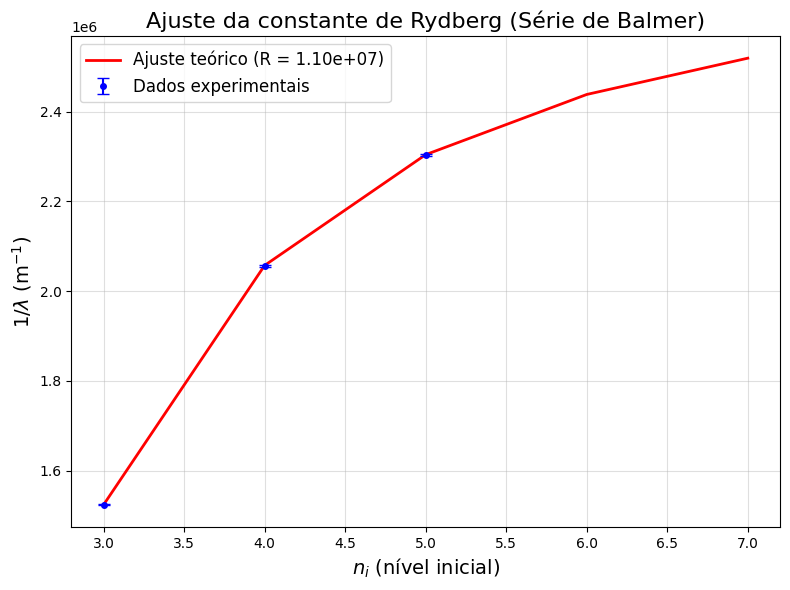

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --------------------------
#  picos detectados!
valores_picos = np.array([434.1, 486.31, 656.09])  # nm
pico_err = np.array([0.39, 0.39, 0.39])  # incertezas em nm

# --------------------------
# Gerar transições da série de Balmer (nf = 2)
def gerar_transicoes_balmer(Z=1, n_max=10, R=1.0973731568508e7):
    transicoes = []
    for n_i in range(3, n_max+1):
        n_f = 2
        inv_lambda = R * Z**2 * (1/n_f**2 - 1/n_i**2)
        lambda_nm = 1e9 / inv_lambda
        transicoes.append((Z, n_i, n_f, lambda_nm))
    return pd.DataFrame(transicoes, columns=["Z", "n_i", "n_f", "lambda_nm"])

df_teo = gerar_transicoes_balmer(Z=1, n_max=10)

# --------------------------
# Casamento automático pico ↔ transição
pares = []
for pico in valores_picos:
    idx = np.argmin(np.abs(df_teo["lambda_nm"] - pico))
    pares.append((pico, *df_teo.iloc[idx]))

df_match = pd.DataFrame(pares, columns=["lambda_exp", "Z", "n_i", "n_f", "lambda_teo"])

# --------------------------
# Ajuste da constante de Rydberg
def modelo(x, R):
    Z, n_i, n_f = x
    return R * Z**2 * (1/n_f**2 - 1/n_i**2)

xdata = np.array([df_match["Z"].values,
                  df_match["n_i"].values,
                  df_match["n_f"].values])
ydata = 1 / (df_match["lambda_exp"].values * 1e-9)

# Erro em 1/λ propagado
yerr = pico_err / (df_match["lambda_exp"].values**2) * 1e9

# Ajuste ponderado
popt, pcov = curve_fit(modelo, xdata, ydata, p0=[1.1e7], sigma=yerr, absolute_sigma=True)

R_est = popt[0]
erro_R = np.sqrt(np.diag(pcov))[0]

print(f"\nConstante de Rydberg estimada: {R_est:.4e} ± {erro_R:.4e} m⁻¹")

# Comparação
R_tab = 1.0973731568508e7
print(f"Valor tabelado: {R_tab:.4e} m⁻¹")
print(f"Desvio relativo: {(R_est-R_tab)/R_tab*100:.3f}%")

# --------------------------
# Gráfico do ajuste
n_i_vals = np.arange(3, 8)
y_teo = modelo((np.ones_like(n_i_vals), n_i_vals, np.full_like(n_i_vals, 2)), R_est)

plt.figure(figsize=(8,6))
plt.errorbar(df_match["n_i"], ydata, yerr=yerr, fmt="o", color="blue",
             label="Dados experimentais", markersize=4, capsize=4, zorder=3)
plt.plot(n_i_vals, y_teo, "r-", lw=2, label=f"Ajuste teórico (R = {R_est:.2e})")

plt.xlabel("$n_i$ (nível inicial)", fontsize=14)
plt.ylabel(r"$1/\lambda$ (m$^{-1}$)", fontsize=14)
plt.title("Ajuste da constante de Rydberg (Série de Balmer)", fontsize=16)
plt.grid(True, alpha=0.4)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()



Constante de Rydberg estimada (ajuste linear): 1.0970e+07 ± 1.8011e+03 m⁻¹
Valor tabelado: 1.0974e+07 m⁻¹
Desvio relativo: -0.038%


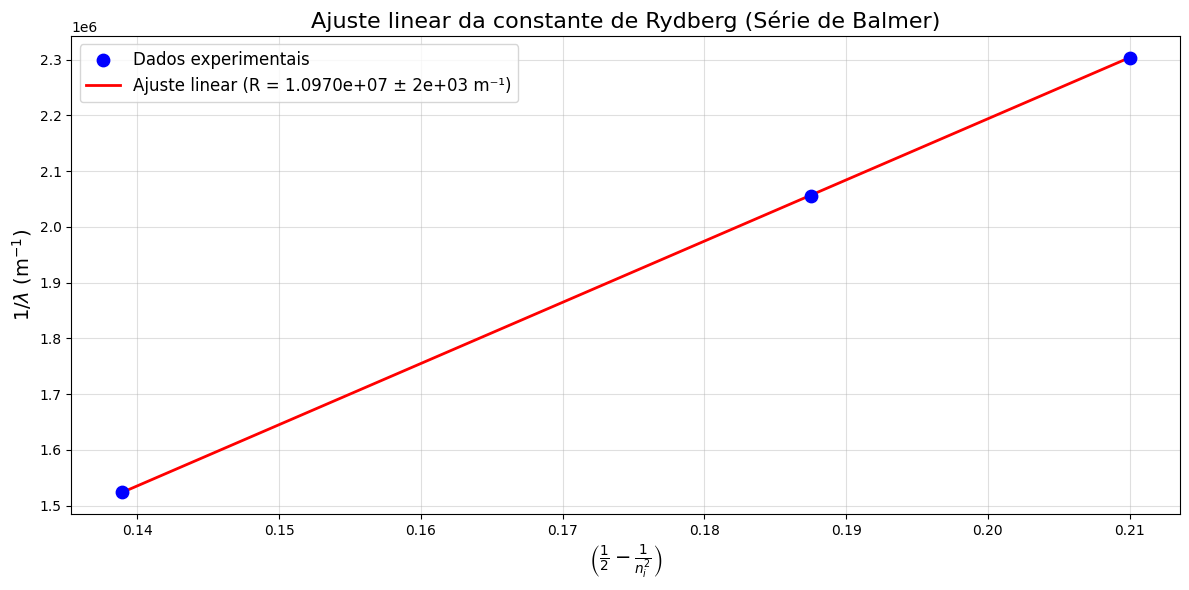

In [ ]:
# --------------------------
# Ajuste linear simples para R
n_f = 2
x_lin = (1/n_f**2 - 1/df_match["n_i"].values**2)
y_lin = 1 / (df_match["lambda_exp"].values * 1e-9)

# Coeficiente angular da reta = R
R_est, _, _, _ = np.linalg.lstsq(x_lin[:, np.newaxis], y_lin, rcond=None)
R_est = R_est[0]

# Estimativa do erro (desvio padrão residual)
residuos = y_lin - R_est * x_lin
sigma2 = np.sum(residuos**2) / (len(y_lin) - 1)
erro_R = np.sqrt(sigma2 / np.sum(x_lin**2))

print(f"\nConstante de Rydberg estimada (ajuste linear): {R_est:.4e} ± {erro_R:.4e} m⁻¹")

# Comparação
R_tab = 1.0973731568508e7
print(f"Valor tabelado: {R_tab:.4e} m⁻¹")
print(f"Desvio relativo: {(R_est-R_tab)/R_tab*100:.3f}%")

# --------------------------
# Gráfico do ajuste
plt.figure(figsize=(12,6))
plt.scatter(x_lin, y_lin, color="blue", label="Dados experimentais", s=80, zorder=3)
plt.plot(x_lin, R_est*x_lin, "r-", lw=2, label=f"Ajuste linear (R = {R_est:.4e} ± {erro_R:.0e} m⁻¹)")

plt.xlabel(r"$\left(\frac{1}{2} - \frac{1}{n_i^2}\right)$", fontsize=14)
plt.ylabel(r"$1/\lambda$ (m$^{-1}$)", fontsize=14)
plt.title("Ajuste linear da constante de Rydberg (Série de Balmer)", fontsize=16)
plt.grid(True, alpha=0.4)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()



Constante de Rydberg estimada (ajuste linear ponderado): 1.0971e+07 ± 4.6263e+03 m⁻¹
Valor tabelado: 1.0968e+07 m⁻¹
Desvio relativo: 0.031%


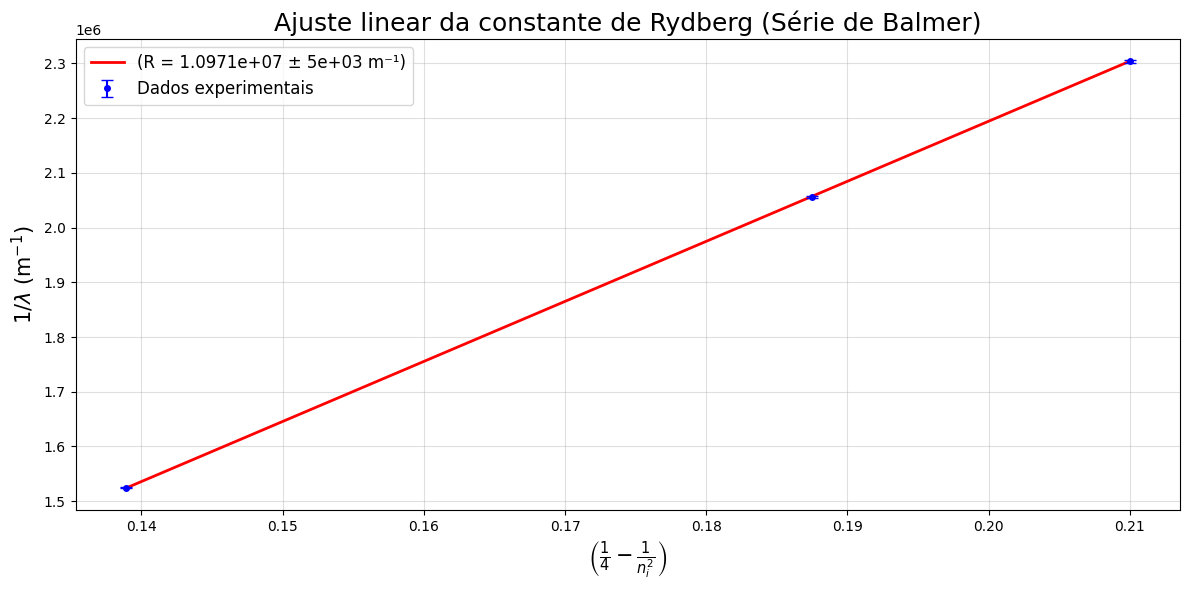

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------
# Picos experimentais (exemplo do seu caso)
valores_picos = np.array([434.1, 486.31, 656.09])  # nm
pico_err = np.array([0.39, 0.39, 0.39])  # incertezas em nm

# --------------------------
# Gerar transições da série de Balmer (nf = 2)
def gerar_transicoes_balmer(Z=1, n_max=10, R=1.0973731568508e7):
    transicoes = []
    for n_i in range(3, n_max+1):
        n_f = 2
        inv_lambda = R * Z**2 * (1/n_f**2 - 1/n_i**2)
        lambda_nm = 1e9 / inv_lambda
        transicoes.append((Z, n_i, n_f, lambda_nm))
    return pd.DataFrame(transicoes, columns=["Z", "n_i", "n_f", "lambda_nm"])

df_teo = gerar_transicoes_balmer(Z=1, n_max=10)

# --------------------------
# Casamento automático pico ↔ transição
pares = []
for pico in valores_picos:
    idx = np.argmin(np.abs(df_teo["lambda_nm"] - pico))
    pares.append((pico, *df_teo.iloc[idx]))

df_match = pd.DataFrame(pares, columns=["lambda_exp", "Z", "n_i", "n_f", "lambda_teo"])

# --------------------------
# Ajuste linear ponderado
n_f = 2
x_lin = (1/n_f**2 - 1/df_match["n_i"].values**2)
y_lin = 1 / (df_match["lambda_exp"].values * 1e-9)

# Propagação do erro: Δ(1/λ) ≈ Δλ / λ²
sigma_y = pico_err * 1e-9 / (df_match["lambda_exp"].values * 1e-9)**2

# Matriz de pesos
W = np.diag(1/sigma_y**2)

# Ajuste linear com pesos (reta pela origem: y = R*x)
R_est = np.linalg.inv(x_lin[:,None].T @ W @ x_lin[:,None]) @ (x_lin[:,None].T @ W @ y_lin[:,None])
R_est = R_est[0,0]

# Incerteza de R
erro_R = np.sqrt(1 / (x_lin[:,None].T @ W @ x_lin[:,None]))[0,0]

print(f"\nConstante de Rydberg estimada (ajuste linear ponderado): {R_est:.4e} ± {erro_R:.4e} m⁻¹")

# Comparação
R_tab = 1.09677576e7
print(f"Valor tabelado: {R_tab:.4e} m⁻¹")
print(f"Desvio relativo: {(R_est-R_tab)/R_tab*100:.3f}%")

# --------------------------
# Gráfico do ajuste
plt.figure(figsize=(12,6))
plt.errorbar(x_lin, y_lin, yerr=sigma_y, fmt="o", color="blue",
             label="Dados experimentais", capsize=4, markersize=4, zorder=3)
plt.plot(x_lin, R_est*x_lin, "r-", lw=2,
         label=f"(R = {R_est:.4e} ± {erro_R:.0e} m⁻¹)")

plt.xlabel(r"$\left(\frac{1}{4} - \frac{1}{n_i^2}\right)$", fontsize=15)
plt.ylabel(r"$1/\lambda$ (m$^{-1}$)", fontsize=15)
plt.title("Ajuste linear da constante de Rydberg (Série de Balmer)", fontsize=18)
plt.grid(True, alpha=0.4)
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig("ajuste linear Rydberg.pdf", format="pdf", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
df_match

,lambda_exp,Z,n_i,n_f,lambda_teo
0,434.10,1.0,5.0,2.0,433.936691
1,486.31,1.0,4.0,2.0,486.009094
2,656.09,1.0,3.0,2.0,656.112276


/tmp/ipython-input-1940528617.py:16: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(arquivo, delim_whitespace=True,
/tmp/ipython-input-1940528617.py:16: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(arquivo, delim_whitespace=True,


Picos Argónio: [415.87 420.26 696.56 706.73 714.57 727.26 738.59 751.47 763.63 772.54
 794.99 801.58 811.59 826.81 842.84 852.64 853.25 867.55 868.77 869.37]
Argónio - Pico em x = 415.87 ± 0.28 (FWHM = 1.35)
Argónio - Pico em x = 420.26 ± 0.37 (FWHM = 1.79)
Argónio - Pico em x = 696.56 ± 0.50 (FWHM = 2.45)
Argónio - Pico em x = 706.73 ± 0.52 (FWHM = 2.54)
Argónio - Pico em x = 714.57 ± 0.60 (FWHM = 2.94)
Argónio - Pico em x = 727.26 ± 0.57 (FWHM = 2.79)
Argónio - Pico em x = 738.59 ± 0.59 (FWHM = 2.87)
Argónio - Pico em x = 751.47 ± 0.65 (FWHM = 3.16)
Argónio - Pico em x = 763.63 ± 0.53 (FWHM = 2.62)
Argónio - Pico em x = 772.54 ± 0.56 (FWHM = 2.76)
Argónio - Pico em x = 794.99 ± 0.59 (FWHM = 2.87)
Argónio - Pico em x = 801.58 ± 0.70 (FWHM = 3.42)
Argónio - Pico em x = 811.59 ± 0.69 (FWHM = 3.36)
Argónio - Pico em x = 826.81 ± 0.84 (FWHM = 4.11)
Argónio - Pico em x = 842.84 ± 0.77 (FWHM = 3.77)
Argónio - Pico em x = 852.64 ± 0.94 (FWHM = 4.63)
Argónio - Pico em x = 853.25 ± 0.08 (FWHM 

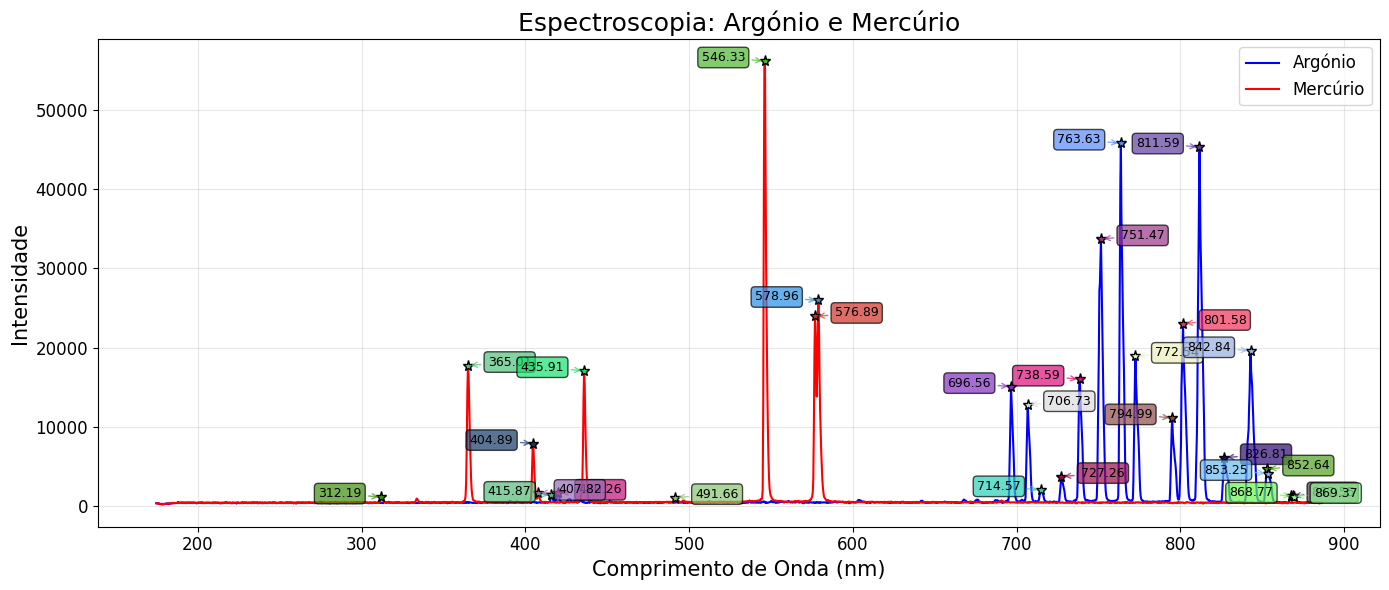

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks, peak_widths
import numpy as np

# Lista de arquivos, cores e labels
arquivos = [
    ('/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/AR_LAMBDA1.txt', 'blue', 'Argónio', 1000),
    ('/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/HG_LAMBDA1.txt', 'red', 'Mercúrio', 1000)
]

plt.figure(figsize=(14,6))

for arquivo, cor, label, altura_minima in arquivos:
    # Leitura do arquivo
    df = pd.read_csv(arquivo, delim_whitespace=True,
                     converters={0: lambda x: float(x.replace(',', '.')),
                                 1: lambda x: float(x.replace(',', '.'))},
                     names=['Comprimento', 'Intensidade'])
    x = df['Comprimento'].values
    y = df['Intensidade'].values

    # Detecta picos
    todos_picos, _ = find_peaks(y, height=altura_minima)
    valores_picos = x[todos_picos]
    print(f'Picos {label}: {valores_picos.round(2)}')

    # Plot do espectro
    plt.plot(x, y, color=cor, label=f'{label}')

    # Gerar cores aleatórias para picos
    cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

    # Anotar picos
    for i, pico in enumerate(todos_picos):
        x_offset = -30 if i % 2 == 0 else 30
        y_offset = 0
        plt.plot(x[pico], y[pico], '*', markersize=8, color=cores_aleatorias[i], markeredgecolor='black')
        plt.annotate(f'{x[pico]:.2f}',
                     xy=(x[pico], y[pico]),
                     xytext=(x_offset, y_offset),
                     textcoords='offset points',
                     ha='center',
                     arrowprops=dict(arrowstyle='->', color=cores_aleatorias[i], lw=1, alpha=0.7),
                     bbox=dict(boxstyle='round,pad=0.3', facecolor=cores_aleatorias[i], alpha=0.7),
                     fontsize=9)

    # FWHM
    results = peak_widths(y, todos_picos, rel_height=0.5)
    for i, idx in enumerate(todos_picos):
        centro = x[idx]
        largura = results[0][i] * (x[1] - x[0])
        erro = largura / (2 * np.sqrt(6))
        print(f"{label} - Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")

# Configurações do gráfico
plt.grid(True, alpha=0.3)
plt.title("Espectroscopia: Argónio e Mercúrio", fontsize=18)
plt.xlabel("Comprimento de Onda (nm)", fontsize=15)
plt.ylabel("Intensidade", fontsize=15)
plt.legend(fontsize=12)
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()


/tmp/ipython-input-1713469013.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,
/tmp/ipython-input-1713469013.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Os valores dos picos são: [312.19 365.01 404.52 435.91 486.31 546.33 576.89 578.96 656.09 696.56
 706.73 714.57 727.26 738.27 751.14 763.31 772.23 794.67 801.27 811.59
 826.5  841.   842.54 852.34]


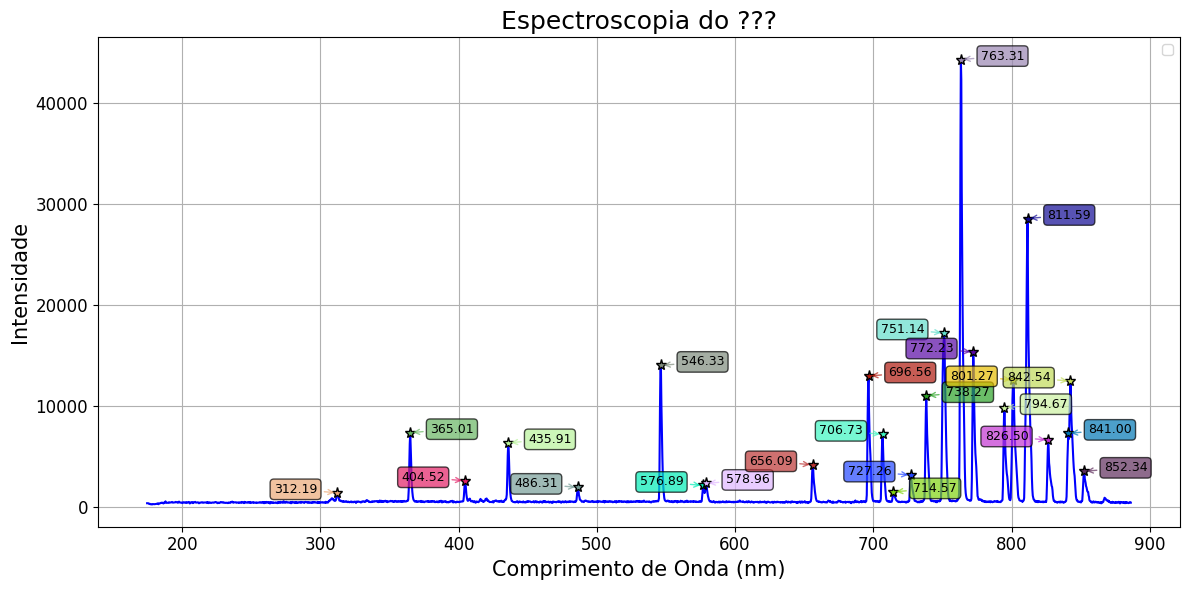

Pico em x = 312.19 ± 0.36 (FWHM = 1.77)
Pico em x = 365.01 ± 0.31 (FWHM = 1.54)
Pico em x = 404.52 ± 0.32 (FWHM = 1.55)
Pico em x = 435.91 ± 0.32 (FWHM = 1.56)
Pico em x = 486.31 ± 0.31 (FWHM = 1.53)
Pico em x = 546.33 ± 0.35 (FWHM = 1.73)
Pico em x = 576.89 ± 0.20 (FWHM = 0.98)
Pico em x = 578.96 ± 0.48 (FWHM = 2.34)
Pico em x = 656.09 ± 0.40 (FWHM = 1.98)
Pico em x = 696.56 ± 0.41 (FWHM = 1.99)
Pico em x = 706.73 ± 0.42 (FWHM = 2.05)
Pico em x = 714.57 ± 0.42 (FWHM = 2.04)
Pico em x = 727.26 ± 0.44 (FWHM = 2.16)
Pico em x = 738.27 ± 0.43 (FWHM = 2.11)
Pico em x = 751.14 ± 0.63 (FWHM = 3.10)
Pico em x = 763.31 ± 0.44 (FWHM = 2.14)
Pico em x = 772.23 ± 0.41 (FWHM = 2.02)
Pico em x = 794.67 ± 0.40 (FWHM = 1.95)
Pico em x = 801.27 ± 0.54 (FWHM = 2.62)
Pico em x = 811.59 ± 0.50 (FWHM = 2.43)
Pico em x = 826.50 ± 0.47 (FWHM = 2.31)
Pico em x = 841.00 ± 0.06 (FWHM = 0.29)
Pico em x = 842.54 ± 0.85 (FWHM = 4.18)
Pico em x = 852.34 ± 0.63 (FWHM = 3.10)


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/Desconhecido_LAMBDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'])

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=1000)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)



plt.grid(True)
plt.title("Espectroscopia do ???",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


/tmp/ipython-input-1028242526.py:24: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(base_path + arquivo, delim_whitespace=True,
/tmp/ipython-input-1028242526.py:24: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(base_path + arquivo, delim_whitespace=True,
/tmp/ipython-input-1028242526.py:24: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(base_path + arquivo, delim_whitespace=True,
/tmp/ipython-input-1028242526.py:24: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(base_path + arquivo, delim_whitespace=True,
/tmp/ipython-input-1028242526.py

Vapor de água - Pico em x = 336.65 ± 0.39 (FWHM = 1.90)
Vapor de água - Pico em x = 357.20 ± 0.38 (FWHM = 1.88)
Vapor de água - Pico em x = 486.31 ± 0.30 (FWHM = 1.45)
Vapor de água - Pico em x = 656.09 ± 0.58 (FWHM = 2.85)
Vapor de água - Pico em x = 776.99 ± 0.34 (FWHM = 1.68)
Hidrogênio - Pico em x = 434.10 ± 0.39 (FWHM = 1.93)
Hidrogênio - Pico em x = 486.31 ± 0.33 (FWHM = 1.62)
Hidrogênio - Pico em x = 656.09 ± 0.31 (FWHM = 1.51)
Criptônio - Pico em x = 557.14 ± 0.33 (FWHM = 1.59)
Criptônio - Pico em x = 586.88 ± 0.32 (FWHM = 1.57)
Criptônio - Pico em x = 758.51 ± 0.05 (FWHM = 0.25)
Criptônio - Pico em x = 760.11 ± 0.38 (FWHM = 1.87)
Criptônio - Pico em x = 769.36 ± 0.46 (FWHM = 2.25)
Criptônio - Pico em x = 785.22 ± 0.33 (FWHM = 1.64)
Criptônio - Pico em x = 805.96 ± 0.31 (FWHM = 1.53)
Criptônio - Pico em x = 811.27 ± 0.38 (FWHM = 1.86)
Criptônio - Pico em x = 819.06 ± 0.33 (FWHM = 1.63)
Criptônio - Pico em x = 826.50 ± 0.23 (FWHM = 1.15)
Criptônio - Pico em x = 828.05 ± 0.06 (FW

/tmp/ipython-input-1028242526.py:24: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(base_path + arquivo, delim_whitespace=True,


Mercúrio - Pico em x = 365.01 ± 0.39 (FWHM = 1.93)
Mercúrio - Pico em x = 404.89 ± 0.33 (FWHM = 1.64)
Mercúrio - Pico em x = 435.91 ± 0.34 (FWHM = 1.68)
Mercúrio - Pico em x = 546.33 ± 0.37 (FWHM = 1.83)
Mercúrio - Pico em x = 576.89 ± 0.20 (FWHM = 0.98)
Mercúrio - Pico em x = 578.96 ± 0.83 (FWHM = 4.07)


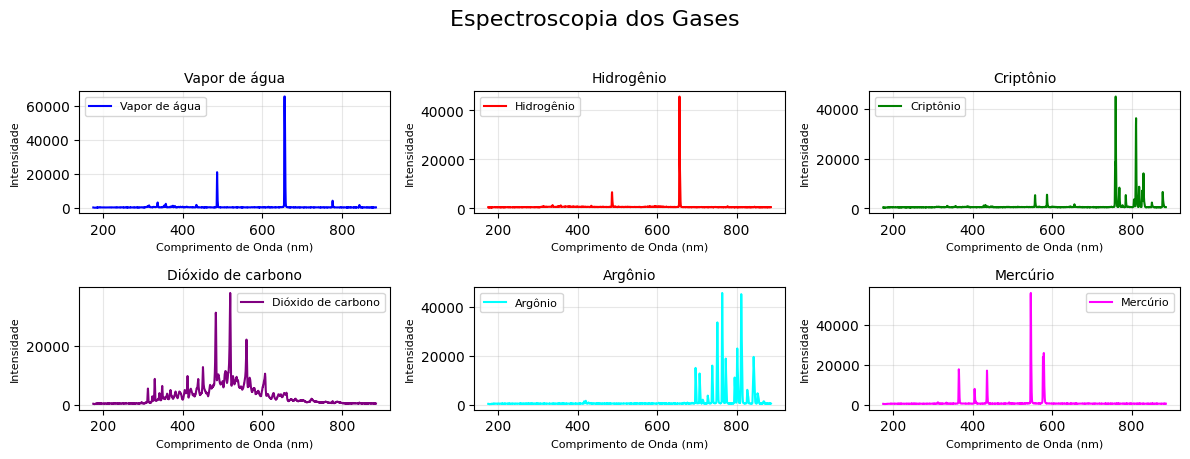

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks, peak_widths
import numpy as np

# Lista de arquivos, labels, cores e altura mínima de pico
gases = [
    ('H2O_LAMBDA1.txt', 'Vapor de água', 'blue', 2000),
    ('H_LAMBDA1.txt', 'Hidrogênio', 'red', 900),
    ('KR_LAMBDA1.txt', 'Criptônio', 'green', 2000),
    ('CO2_LAMBDA1.txt', 'Dióxido de carbono', 'purple', 1000),
    ('AR_LAMBDA1.txt', 'Argônio', 'cyan', 1000),
    ('HG_LAMBDA1.txt', 'Mercúrio', 'magenta', 2000)
]

# Caminho base
base_path = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/'

# Criar figura e subplots
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 6))
axes = axes.flatten()  # Facilita o acesso sequencial aos subplots

for i, (arquivo, label, cor, altura_minima) in enumerate(gases):
    df = pd.read_csv(base_path + arquivo, delim_whitespace=True,
                     converters={0: lambda x: float(x.replace(',', '.')),
                                 1: lambda x: float(x.replace(',', '.'))},
                     names=['Comprimento', 'Intensidade'])

    x = df['Comprimento'].values
    y = df['Intensidade'].values

    # Detecta picos
    todos_picos, _ = find_peaks(y, height=altura_minima)

    # Filtragem específica para Hidrogênio
    if 'H_LAMBDA1' in arquivo:
        todos_picos = [p for p in todos_picos if x[p] > 400]

    ax = axes[i]
    ax.plot(x, y, color=cor, label=label)

    # Configurações de cada subplot
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Comprimento de Onda (nm)", fontsize=8)
    ax.set_ylabel("Intensidade", fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

    # Cálculo de FWHM
    results = peak_widths(y, todos_picos, rel_height=0.5)
    for j, idx in enumerate(todos_picos):
        centro = x[idx]
        largura = results[0][j] * (x[1] - x[0])
        erro = largura / (2 * np.sqrt(6))
        print(f"{label} - Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")

# Remover subplots extras se houver
for j in range(len(gases), len(axes)):
    fig.delaxes(axes[j])

# Título geral
fig.suptitle("Espectroscopia dos Gases", fontsize=16, y=1.02)

plt.tight_layout()
plt.show()


/tmp/ipython-input-2054659267.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


Os valores dos picos são: [365.01 404.89 435.91 546.33 576.89 578.96]


/tmp/ipython-input-2054659267.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


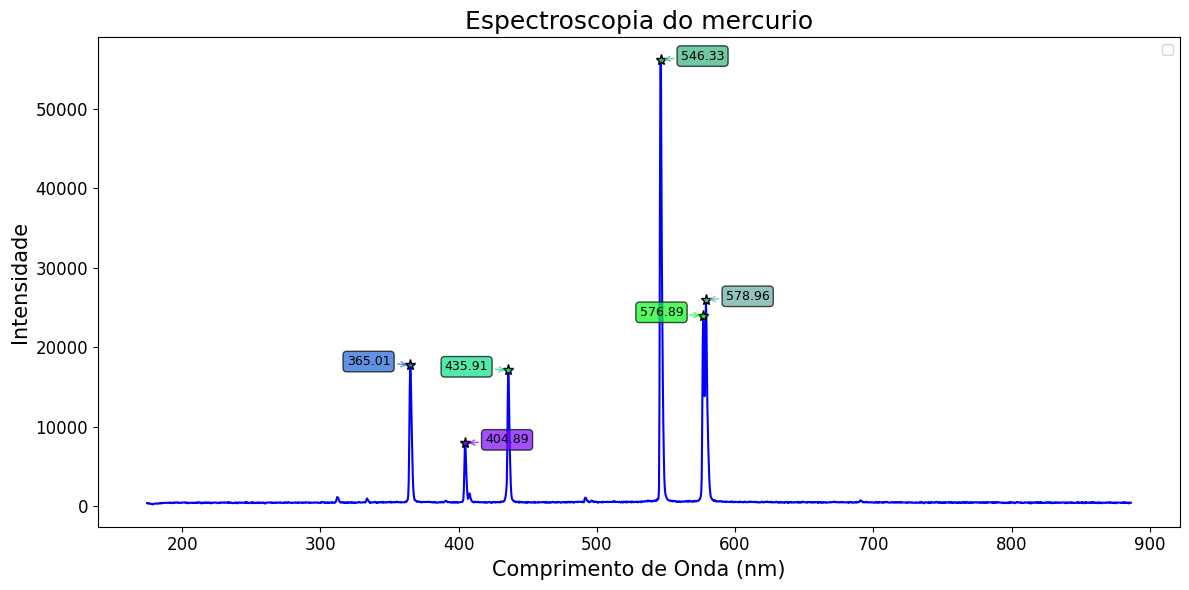

Pico em x = 365.01 ± 0.39 (FWHM = 1.93)
Pico em x = 404.89 ± 0.33 (FWHM = 1.64)
Pico em x = 435.91 ± 0.34 (FWHM = 1.68)
Pico em x = 546.33 ± 0.37 (FWHM = 1.83)
Pico em x = 576.89 ± 0.20 (FWHM = 0.98)
Pico em x = 578.96 ± 0.83 (FWHM = 4.07)


In [ ]:

# Caminho para o arquivo
url = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/HG_LAMBDA1.txt'

# Leitura do arquivo usando pandas
df = pd.read_csv(url, delim_whitespace=True,
                 converters={0: lambda x: float(x.replace(',', '.')),
                             1: lambda x: float(x.replace(',', '.'))},
                 names=['Comprimento', 'Intensidade'],)

x = df['Comprimento'].values
y = df['Intensidade'].values

# Detecta picos principais com altura mínima
todos_picos, _ = find_peaks(y, height=2000)

valores_picos = x[todos_picos]

print(f'Os valores dos picos são: {valores_picos.round(2)}')

# Plotagem
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='blue')

# Gerar cores aleatórias com NumPy
cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

# Anotar os picos no gráfico
for i, pico in enumerate(todos_picos):
    cor = cores_aleatorias[i]
    plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black')

    # Alternância entre esquerda e direita
    x_offset = -30 if i % 2 == 0 else 30
    y_offset = 0

    plt.annotate(f'{x[pico]:.2f}',
                 xy=(x[pico], y[pico]),
                 xytext=(x_offset, y_offset),
                 textcoords='offset points',
                 ha='center',
                 arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.7),
                 bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.7),
                 fontsize=9)

# Estética do gráfico

plt.title("Espectroscopia do mercurio",fontsize=18)
plt.xlabel("Comprimento de Onda (nm)",fontsize=15)
plt.ylabel("Intensidade",fontsize=15)
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Cálculo de Largura a Meia Altura (FWHM) e incertezas
results = peak_widths(y, todos_picos, rel_height=0.5)

for i, idx in enumerate(todos_picos):
    centro = x[idx]
    largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
    erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

    print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")


In [9]:

def analise_spectral(url):
    def wavelength_to_rgb(wavelength, gamma=0.8):
        ''' taken from http://www.noah.org/wiki/Wavelength_to_RGB_in_Python
        This converts a given wavelength of light to an
        approximate RGB color value. The wavelength must be given
        in nanometers in the range from 380 nm through 750 nm
        (789 THz through 400 THz).

        Based on code by Dan Bruton
        http://www.physics.sfasu.edu/astro/color/spectra.html
        Additionally alpha value set to 0.5 outside range
        '''
        wavelength = float(wavelength)
        if wavelength >= 380 and wavelength <= 750:
            A = 1.
        else:
            A=0.5
        if wavelength < 380:
            wavelength = 380.
        if wavelength >750:
            wavelength = 750.
        if wavelength >= 380 and wavelength <= 440:
            attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
            R = ((-(wavelength - 440) / (440 - 380)) * attenuation) ** gamma
            G = 0.0
            B = (1.0 * attenuation) ** gamma
        elif wavelength >= 440 and wavelength <= 490:
            R = 0.0
            G = ((wavelength - 440) / (490 - 440)) ** gamma
            B = 1.0
        elif wavelength >= 490 and wavelength <= 510:
            R = 0.0
            G = 1.0
            B = (-(wavelength - 510) / (510 - 490)) ** gamma
        elif wavelength >= 510 and wavelength <= 580:
            R = ((wavelength - 510) / (580 - 510)) ** gamma
            G = 1.0
            B = 0.0
        elif wavelength >= 580 and wavelength <= 645:
            R = 1.0
            G = (-(wavelength - 645) / (645 - 580)) ** gamma
            B = 0.0
        elif wavelength >= 645 and wavelength <= 750:
            attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
            R = (1.0 * attenuation) ** gamma
            G = 0.0
            B = 0.0
        else:
            R = 0.0
            G = 0.0
            B = 0.0
        return (R,G,B,A)

    # Leitura do arquivo usando pandas
    df = pd.read_csv(url, delim_whitespace=True,
                    converters={0: lambda x: float(x.replace(',', '.')),
                                1: lambda x: float(x.replace(',', '.'))},
                    names=['Comprimento', 'Intensidade'])

    x = df['Comprimento'].values
    y = df['Intensidade'].values

    # Detecta picos principais com altura mínima
    todos_picos, _ = find_peaks(y, height=5000, prominence=400)

    valores_picos = x[todos_picos]
    peaks_filtrados = [p for p in todos_picos if 350 <= x[p] <= 700]
    print(f'Os valores dos picos são: {valores_picos.round(2)}')

    # Plotagem
    plt.figure(figsize=(10.29, 8.01))
    plt.plot(x, y, color='black')

    # Gerar cores aleatórias com NumPy
    cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

    cores_aleatorias =[
        "#7F00FF",  # 364.4 nm - UV/violeta (representação)
        "#550082",  # 404.32 nm - violeta
        "#1D00F5",  # 435.74 nm - azul-violeta
        "#96FF00",  # 545.83 nm - verde intenso
        "#F6FF00",  # 576.73 nm - amarelo
        "#FFEE00",  # 578.8 nm - amarelo (segunda linha)
    ]

    labels_hg = [
    r"$6^3D \rightarrow 6^3P_2$",  # 364.4 nm
    r"$7^3S \rightarrow 6^3P_0$",  # 404.32 nm
    r"$7^3S \rightarrow 6^3P_1$",  # 435.74 nm
    r"$7^3S \rightarrow 6^3P_1$",  # 545.83 nm
    r"$6^3D \rightarrow 6^1P_2$",  # 576.73 nm
    r"$6^3D \rightarrow 6^1P_2$",  # 578.8 nm
]

    # Anotar os picos no gráfico
    for i, pico in enumerate(peaks_filtrados):
        cor = cores_aleatorias[i]
        label = labels_hg[i % len(labels_hg)]
        plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black',label=label)

        # Alternância entre esquerda e direita
        x_offset = 50 if i % 2 == 0 else 50
        y_offset = 0

        plt.annotate(f'{x[pico]:.2f}',
                    xy=(x[pico], y[pico]),
                    xytext=(x_offset, y_offset),
                    textcoords='offset points',
                    ha='center',
                    arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.5),
                    bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.6),
                    fontsize=10.5)

    #######Espectro sob a curva########
    step = max(1, len(x) // 500)  # Ajusta o passo baseado no número de pontos
    for i in range(0, len(x) - 1, step):
        if 380 <= x[i] <= 780:
            lambda_medio = (x[i] + x[i+1]) / 2
            rgb = wavelength_to_rgb(lambda_medio)

            plt.fill_between([x[i], x[min(i+step, len(x)-1)]],
                            [y[i], y[min(i+step, len(x)-1)]],
                            color=rgb, alpha=0.6)

    plt.title("Espectroscopia do HG",fontsize=18)
    plt.xlabel("Comprimento de Onda (nm)",fontsize=20)
    plt.ylabel("Intensidade",fontsize=20)
    plt.legend(fontsize=12)
    plt.tick_params(labelsize=20)
    plt.tight_layout()
    plt.xlim(350,620)
    plt.show()

    # Cálculo de Largura a Meia Altura (FWHM) e incertezas
    results = peak_widths(y, todos_picos, rel_height=0.5)

    for i, idx in enumerate(todos_picos):
        centro = x[idx]
        largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
        erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

        print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")

/tmp/ipython-input-2376743649.py:55: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True,


Os valores dos picos são: [365.01 404.89 435.91 546.33 576.89 578.96]


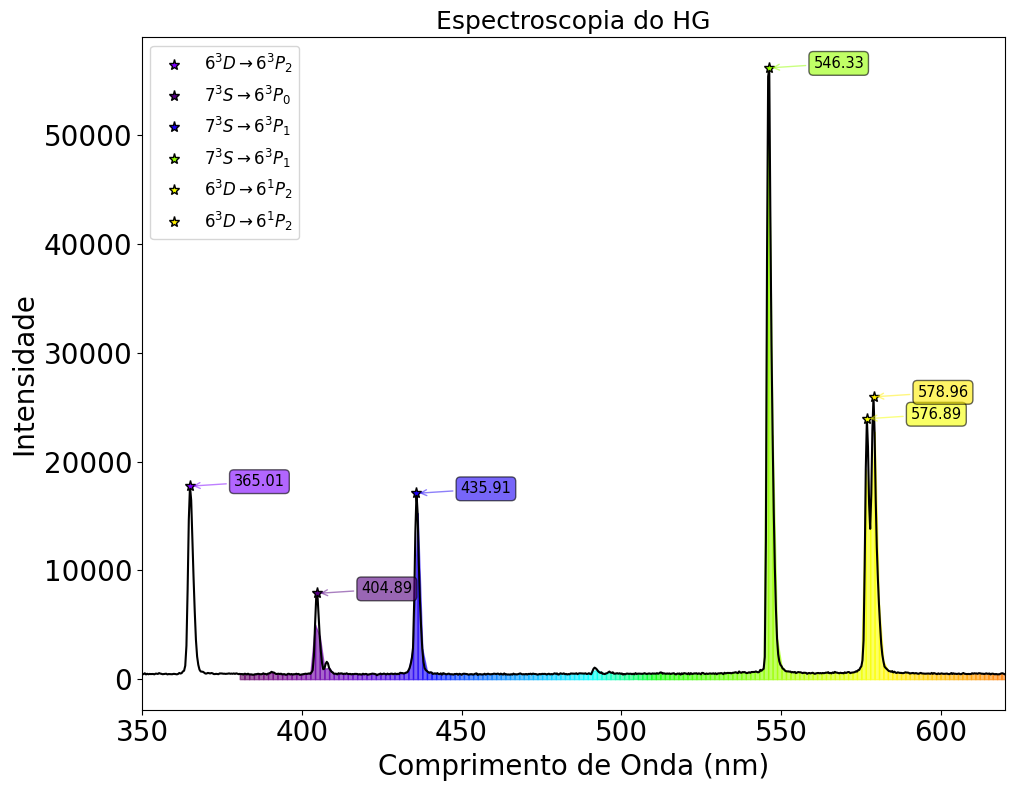

Pico em x = 365.01 ± 0.39 (FWHM = 1.93)
Pico em x = 404.89 ± 0.33 (FWHM = 1.64)
Pico em x = 435.91 ± 0.34 (FWHM = 1.68)
Pico em x = 546.33 ± 0.37 (FWHM = 1.83)
Pico em x = 576.89 ± 0.20 (FWHM = 0.98)
Pico em x = 578.96 ± 0.83 (FWHM = 4.07)


In [10]:
urlspectra1 = '/content/drive/MyDrive/2025s2/F 740/Espect./Medicoes/GASES/HG_LAMBDA1.txt'
analise_spectral(urlspectra1)
